# Telecom Customer Churn Prediction
### End-to-end, leakage-aware machine learning project

**Objective:** predict which telecom customers are likely to churn, evaluate models using metrics appropriate for an imbalanced target, interpret the strongest drivers, and export a reusable prediction pipeline.

**Dataset:** `Customer-Churn.csv` (Telco customer churn; 7,043 records in the supplied file).



> The notebook deliberately starts with class weighting and standard preprocessing rather than blindly applying SMOTE to one-hot encoded categorical features. Resampling can be tested later inside an imbalanced-learn pipeline if justified by cross-validation.

## 1. Imports and configuration

In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, accuracy_score, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
DATA_PATH = Path("Customer-Churn.csv")

In [1]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.0 MB/s eta 0:00:00


## 2. Load and audit the data
Place `Customer-Churn.csv` in the same folder as this notebook, or update `DATA_PATH`.

In [4]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nTarget distribution:")
display(df["Churn"].value_counts(dropna=False).to_frame("count"))
display((df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

Duplicate rows: 0
Missing values by column:


,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Target distribution:


,count
Churn,
No,5174
Yes,1869


,percent
Churn,
No,73.46
Yes,26.54


## 3. Clean target and numeric fields
`TotalCharges` is stored as text in this dataset. Blank strings are converted to missing values and imputed within the training pipeline.

In [5]:
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data = data.dropna(subset=["Churn"]).copy()
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
if data["Churn"].isna().any():
    raise ValueError("Unexpected target labels found. Inspect data['Churn'].unique().")

# CustomerID is an identifier, not a predictive feature.
X = data.drop(columns=["Churn", "customerID"], errors="ignore")
y = data["Churn"].astype(int)

print("Rows retained:", len(data))
print("TotalCharges missing after numeric conversion:", X["TotalCharges"].isna().sum())
print(f"Churn rate: {y.mean():.2%}")

Rows retained: 7043
TotalCharges missing after numeric conversion: 11
Churn rate: 26.54%


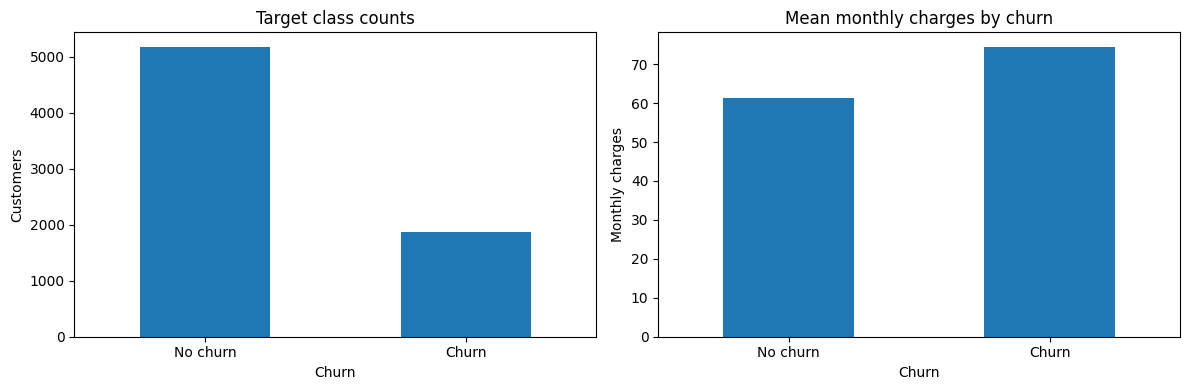

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.value_counts().sort_index().rename(index={0: "No churn", 1: "Churn"}).plot(kind="bar", ax=axes[0])
axes[0].set_title("Target class counts")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=0)
data.groupby("Churn")["MonthlyCharges"].mean().rename(index={0: "No churn", 1: "Churn"}).plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean monthly charges by churn")
axes[1].set_ylabel("Monthly charges")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4. Split once, before learning preprocessing
The test set is held back until final evaluation. Stratification preserves the approximate churn rate in both partitions.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print(f"Training churn rate: {y_train.mean():.2%} | Test churn rate: {y_test.mean():.2%}")

Training rows: 5634 | Test rows: 1409
Training churn rate: 26.54% | Test churn rate: 26.54%


## 5. Preprocessing pipeline
Numeric columns are imputed and standardized; categorical columns are imputed and one-hot encoded. All transformations are fitted within each CV fold.

In [9]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15


## 6. Establish a baseline and compare models
Average precision (area under the precision-recall curve) is the primary selection metric because churn is the minority class. Accuracy alone can hide poor churn detection.

,Optional model,Status
0,XGBoost,included
1,LightGBM,included
2,CatBoost,included


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Model comparison ranked by mean cross-validated Average Precision (PR-AUC).
Primary metric: Average Precision; secondary metrics: ROC-AUC, recall, precision, F1, accuracy.


,Model,cv_fit_seconds,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,recall_mean,recall_std,precision_mean,precision_std,accuracy_mean,accuracy_std
0,Gradient Boosting,9.596,0.669,0.022,0.850,0.012,0.584,0.025,0.515,0.027,0.674,0.026,0.805,0.011
1,CatBoost,5.535,0.666,0.019,0.848,0.009,0.590,0.027,0.525,0.028,0.673,0.034,0.806,0.013
2,XGBoost,1.742,0.662,0.021,0.845,0.010,0.584,0.027,0.522,0.029,0.662,0.034,0.802,0.013
3,Logistic Regression,0.810,0.660,0.020,0.846,0.012,0.628,0.023,0.801,0.038,0.516,0.019,0.748,0.015
4,LightGBM,2.075,0.645,0.025,0.836,0.009,0.624,0.013,0.722,0.019,0.549,0.012,0.769,0.008
5,Random Forest,9.310,0.638,0.026,0.837,0.009,0.615,0.022,0.639,0.026,0.592,0.021,0.788,0.012
6,Naive Bayes (Gaussian),0.487,0.615,0.015,0.821,0.012,0.597,0.009,0.848,0.021,0.461,0.009,0.697,0.009
7,Support Vector Machine (RBF),39.967,0.607,0.021,0.827,0.009,0.624,0.021,0.782,0.038,0.519,0.014,0.750,0.011
8,Decision Tree,0.560,0.606,0.011,0.808,0.008,0.598,0.018,0.764,0.023,0.492,0.019,0.727,0.016
9,K-Nearest Neighbors,0.977,0.569,0.033,0.805,0.013,0.556,0.018,0.534,0.016,0.579,0.023,0.773,0.010


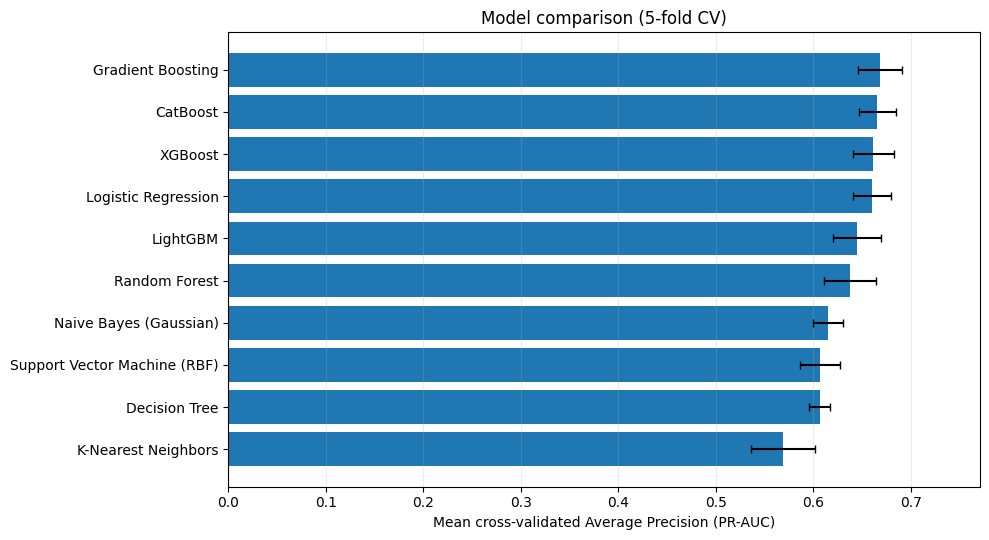

Selected model by mean CV Average Precision: Gradient Boosting


In [10]:
# All models use the same stratified folds and training split.
# Average Precision (PR-AUC) is the primary selection metric because churn is imbalanced.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone
import importlib.util
import time

def make_preprocessor(dense=False):
    """Create a fresh preprocessor for each model pipeline."""
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=not dense)
    except TypeError:  # compatibility with older scikit-learn
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=not dense)
    numeric_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features)
    ])


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=15, weights="distance", n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=10, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Support Vector Machine (RBF)": SVC(
        C=1.0, kernel="rbf", probability=True, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        random_state=RANDOM_STATE
    ),
}

# Optional gradient-boosting libraries. If unavailable, the notebook continues
# and reports which candidates were skipped.
optional_model_status = {}
if importlib.util.find_spec("xgboost") is not None:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=250, max_depth=4, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85,
        eval_metric="logloss", random_state=RANDOM_STATE,
        n_jobs=-1
    )
    optional_model_status["XGBoost"] = "included"
else:
    optional_model_status["XGBoost"] = "skipped: package not installed"

if importlib.util.find_spec("lightgbm") is not None:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        n_estimators=250, learning_rate=0.05, num_leaves=31,
        class_weight="balanced", random_state=RANDOM_STATE,
        verbosity=-1, n_jobs=-1
    )
    optional_model_status["LightGBM"] = "included"
else:
    optional_model_status["LightGBM"] = "skipped: package not installed"

if importlib.util.find_spec("catboost") is not None:
    from catboost import CatBoostClassifier
    models["CatBoost"] = CatBoostClassifier(
        iterations=250, depth=5, learning_rate=0.05,
        loss_function="Logloss", verbose=False,
        random_seed=RANDOM_STATE, thread_count=-1,
        allow_writing_files=False
    )
    optional_model_status["CatBoost"] = "included"
else:
    optional_model_status["CatBoost"] = "skipped: package not installed"

display(pd.DataFrame(
    [{"Optional model": name, "Status": status}
     for name, status in optional_model_status.items()]
))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy",
}

cv_rows = []
pipelines = {}
fit_times = {}
for name, estimator in models.items():
    # GaussianNB requires dense arrays; all other estimators can use sparse one-hot features.
    model_preprocessor = make_preprocessor(dense=(name == "Naive Bayes (Gaussian)"))
    pipe = Pipeline(steps=[("preprocess", model_preprocessor), ("model", estimator)])
    pipelines[name] = pipe
    start = time.time()
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False, error_score="raise"
    )
    fit_times[name] = time.time() - start
    row = {"Model": name, "cv_fit_seconds": fit_times[name]}
    for metric in scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values(
    "average_precision_mean", ascending=False
).reset_index(drop=True)

print("Model comparison ranked by mean cross-validated Average Precision (PR-AUC).")
print("Primary metric: Average Precision; secondary metrics: ROC-AUC, recall, precision, F1, accuracy.")
display(cv_results.round(3))

# Plot the primary selection metric with fold-to-fold standard deviation.
plot_results = cv_results.sort_values("average_precision_mean", ascending=True)
fig, ax = plt.subplots(figsize=(10, max(5, 0.55 * len(plot_results))))
ax.barh(
    plot_results["Model"],
    plot_results["average_precision_mean"],
    xerr=plot_results["average_precision_std"],
    capsize=3
)
ax.set_xlabel("Mean cross-validated Average Precision (PR-AUC)")
ax.set_title("Model comparison (5-fold CV)")
ax.set_xlim(0, min(1.0, max(0.2, (plot_results["average_precision_mean"] + plot_results["average_precision_std"]).max() + 0.08)))
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

best_name = cv_results.iloc[0]["Model"]
best_pipeline = pipelines[best_name]
print(f"Selected model by mean CV Average Precision: {best_name}")


### Model comparison methodology

Candidate models are evaluated on the same stratified training folds using identical input features and preprocessing principles. **Mean Average Precision (PR-AUC)** is the primary selection metric because churn is an imbalanced target; ROC-AUC, precision, recall, F1, accuracy, fold standard deviations and fit time are reported as supporting measures. The held-out test set is reserved for final evaluation after model selection. XGBoost, LightGBM and CatBoost are included only when their packages are installed; otherwise the notebook reports that they were skipped.

These are initial model configurations, not fully tuned models. For a final comparison, tune promising candidates within cross-validation and compare threshold-dependent metrics at a threshold selected from training-only out-of-fold predictions.

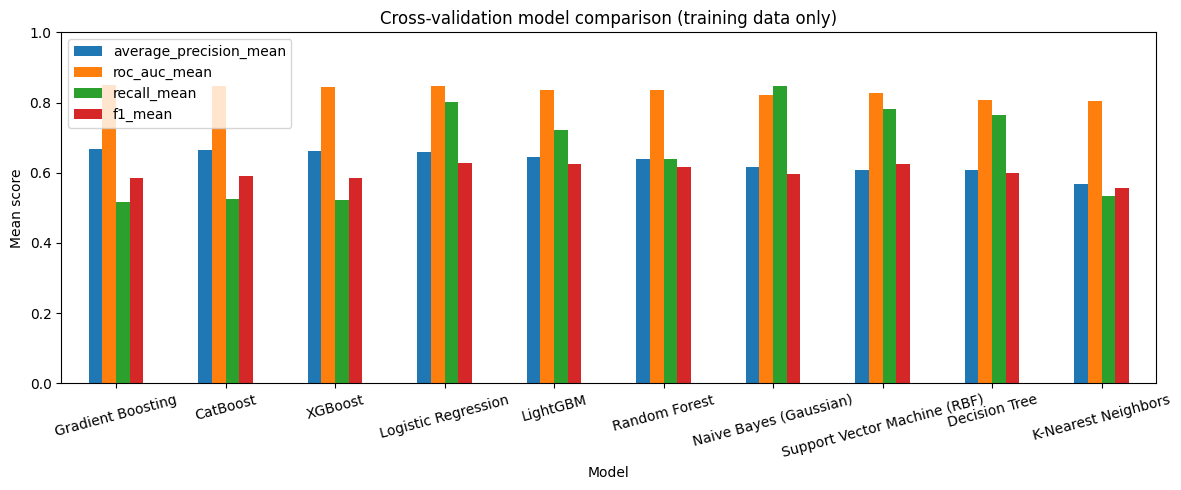

Selected by mean CV average precision: Gradient Boosting


In [11]:
ax = cv_results.set_index("Model")[["average_precision_mean", "roc_auc_mean", "recall_mean", "f1_mean"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1)
)
ax.set_title("Cross-validation model comparison (training data only)")
ax.set_ylabel("Mean score")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

best_name = cv_results.iloc[0]["Model"]
best_pipeline = pipelines[best_name]
print("Selected by mean CV average precision:", best_name)

## 7. Probability calibration and decision-threshold selection

A probability of 0.70 should correspond to roughly a 70% event rate among similar predictions. Calibration is important when scores will drive business economics. We use sigmoid calibration with cross-validation on training data only.

The threshold is selected from out-of-fold calibrated training probabilities, not from the held-out test set.

In [12]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import brier_score_loss
from sklearn.base import clone

# Out-of-fold calibrated probabilities for threshold selection.
# Outer CV estimates generalization; calibration is fitted inside each outer training fold.
calibrated_for_oof = CalibratedClassifierCV(
    estimator=clone(best_pipeline), method="sigmoid", cv=3
)
oof_prob = cross_val_predict(
    calibrated_for_oof, X_train, y_train, cv=3,
    method="predict_proba", n_jobs=-1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_idx = int(np.nanargmax(f1_values))
chosen_threshold = float(thresholds[best_idx])
print(f"Training OOF calibrated threshold selected for F1: {chosen_threshold:.3f}")
print(f"OOF precision: {precision[best_idx]:.3f} | OOF recall: {recall[best_idx]:.3f} | OOF F1: {f1_values[best_idx]:.3f}")

# Fit final calibrated model on all training data.
calibrated_model = CalibratedClassifierCV(
    estimator=clone(best_pipeline), method="sigmoid", cv=5
)
calibrated_model.fit(X_train, y_train)

Training OOF calibrated threshold selected for F1: 0.317
OOF precision: 0.563 | OOF recall: 0.741 | OOF F1: 0.640


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocess',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median')),
                                                                                                   ('scaler',
                                                                                                    StandardScaler())]),
                                                                                   ['SeniorCitizen',
                                                                                    'tenure',
                                                                                    'MonthlyCharges',
                                                                                    'TotalCharges']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                                   ('onehot',
                                                                                                    OneHotE...wn='ignore'))]),
                                                                                   ['gender',
                                                                                    'Partner',
                                                                                    'Dependents',
                                                                                    'PhoneService',
                                                                                    'MultipleLines',
                                                                                    'InternetService',
                                                                                    'OnlineSecurity',
                                                                                    'OnlineBackup',
                                                                                    'DeviceProtection',
                                                                                    'TechSupport',
                                                                                    'StreamingTV',
                                                                                    'StreamingMovies',
                                                                                    'Contract',
                                                                                    'PaperlessBilling',
                                                                                    'PaymentMethod'])])),
                                                 ('model',
                                                  GradientBoostingClassifier(learning_rate=0.05,
                                                                             max_depth=2,
                                                                             n_estimators=150,
                                                                             random_state=42))]))

## 8. Fit final model and evaluate once on the held-out test set

In [13]:
test_prob = calibrated_model.predict_proba(X_test)[:, 1]
test_pred_050 = (test_prob >= 0.50).astype(int)
test_pred_tuned = (test_prob >= chosen_threshold).astype(int)

def metric_row(label, y_true, pred, prob):
    return {
        "Decision rule": label,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC (average precision)": average_precision_score(y_true, prob),
        "Brier score (lower is better)": brier_score_loss(y_true, prob)
    }

test_results = pd.DataFrame([
    metric_row("Calibrated — threshold 0.50", y_test, test_pred_050, test_prob),
    metric_row(f"Calibrated — threshold {chosen_threshold:.3f}", y_test, test_pred_tuned, test_prob)
])
display(test_results.set_index("Decision rule").round(3))
print("\nClassification report at selected threshold:")
print(classification_report(y_test, test_pred_tuned, target_names=["No churn", "Churn"], zero_division=0))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (average precision),Brier score (lower is better)
Decision rule,,,,,,,
Calibrated — threshold 0.50,0.803,0.662,0.524,0.585,0.846,0.664,0.135
Calibrated — threshold 0.317,0.768,0.545,0.757,0.634,0.846,0.664,0.135



Classification report at selected threshold:
              precision    recall  f1-score   support

    No churn       0.90      0.77      0.83      1035
       Churn       0.55      0.76      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



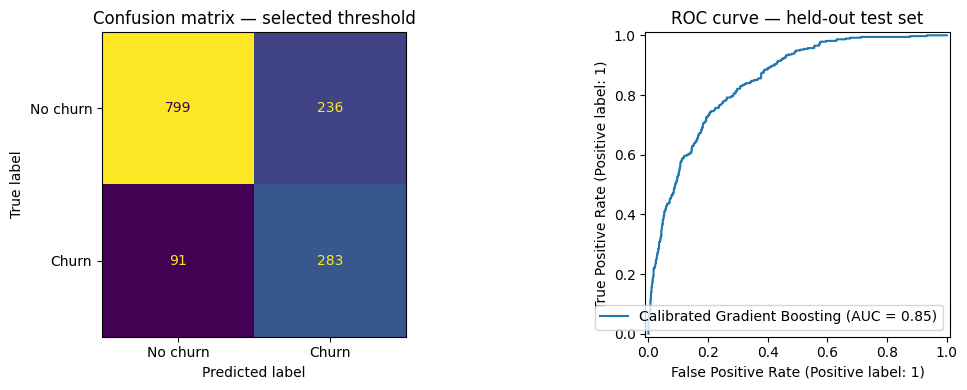

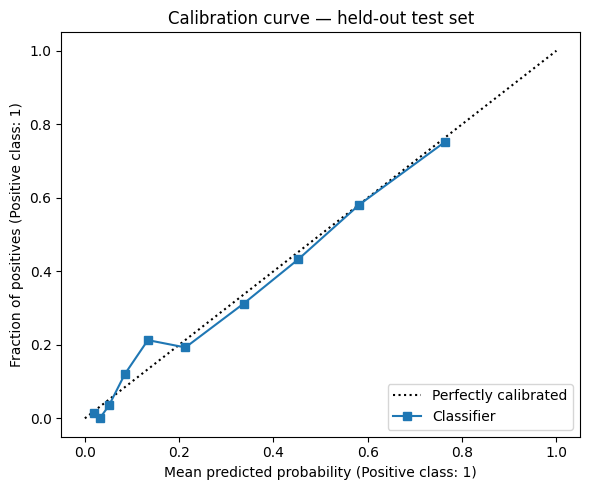

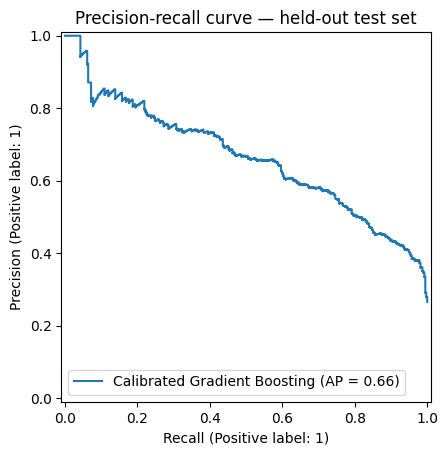

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred_tuned, display_labels=["No churn", "Churn"], ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion matrix — selected threshold")
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=f"Calibrated {best_name}")
axes[1].set_title("ROC curve — held-out test set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, test_prob, n_bins=10, strategy="quantile", ax=ax)
ax.set_title("Calibration curve — held-out test set")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob, name=f"Calibrated {best_name}")
plt.title("Precision-recall curve — held-out test set")
plt.show()

## 9. Retention economics: prioritize outreach by expected value

A high churn probability does not automatically mean a customer is worth contacting. This section combines calibrated churn probability with explicit business assumptions. **All default monetary values below are illustrative placeholders; replace them with company-approved estimates.** The save probability is a campaign assumption, not something inferred from this churn model.

In [16]:
# Illustrative business assumptions — replace with validated company values.
CONTACT_COST_INR = 100.0              # cost to contact one customer
MONTHLY_CONTRIBUTION_INR = 500.0      # contribution margin, not revenue
MONTHS_OF_VALUE_SAVED = 6              # expected months retained if campaign succeeds
CAMPAIGN_SAVE_PROBABILITY = 0.25       # probability an outreach saves a customer
WEEKLY_CONTACT_CAPACITY = 500          # operational outreach capacity

value_if_saved = MONTHLY_CONTRIBUTION_INR * MONTHS_OF_VALUE_SAVED
scored_customers = X_test.copy()
scored_customers["actual_churn"] = y_test
scored_customers["churn_probability"] = test_prob
scored_customers["expected_retained_value_inr"] = (
    scored_customers["churn_probability"]
    * CAMPAIGN_SAVE_PROBABILITY
    * value_if_saved
)
scored_customers["expected_net_value_inr"] = (
    scored_customers["expected_retained_value_inr"] - CONTACT_COST_INR
)
scored_customers["recommended_for_outreach"] = scored_customers["expected_net_value_inr"] > 0

# Rank only economically positive candidates, then respect the contact capacity.
positive_candidates = scored_customers[
    scored_customers["expected_net_value_inr"] > 0
].sort_values("expected_net_value_inr", ascending=False)
outreach_list = positive_candidates.head(WEEKLY_CONTACT_CAPACITY).copy()

expected_gross_value = outreach_list["expected_retained_value_inr"].sum()
expected_contact_cost = len(outreach_list) * CONTACT_COST_INR
expected_net_value = expected_gross_value - expected_contact_cost

print(f"Customers eligible by positive expected value: {len(positive_candidates):,}")
print(f"Customers selected within capacity: {len(outreach_list):,}")
print(f"Illustrative expected retained value: ₹{expected_gross_value:,.0f}")
print(f"Illustrative contact cost: ₹{expected_contact_cost:,.0f}")
print(f"Illustrative expected net value: ₹{expected_net_value:,.0f}")
display(outreach_list[[
    "churn_probability", "expected_retained_value_inr",
    "expected_net_value_inr", "actual_churn"
]].head(10).round(3))

Customers eligible by positive expected value: 777
Customers selected within capacity: 500
Illustrative expected retained value: ₹211,239
Illustrative contact cost: ₹50,000
Illustrative expected net value: ₹161,239


,churn_probability,expected_retained_value_inr,expected_net_value_inr,actual_churn
3380,0.913,684.683,584.683,1
6866,0.903,677.548,577.548,1
4585,0.897,672.404,572.404,1
2797,0.875,656.300,556.300,1
6748,0.874,655.434,555.434,1
6623,0.870,652.230,552.230,1
2631,0.870,652.159,552.159,1
6365,0.870,652.159,552.159,1
642,0.868,650.636,550.636,1
2397,0.865,648.512,548.512,1


**Interpretation and limitations:** this is a scenario calculator, not a causal ROI estimate. It assumes the save probability and retained contribution are valid and that outreach costs are linear. Validate assumptions with randomized campaign tests and avoid treating model-predicted risk as proof that a customer can be saved.

## 10. Interpret the model with permutation importance
Permutation importance is calculated on the held-out test set and measures how much the selected scoring metric deteriorates when a feature is shuffled. Treat it as predictive importance, not causality.

,feature,importance_mean,importance_std
4,tenure,0.1258,0.0085
14,Contract,0.0697,0.0061
7,InternetService,0.0338,0.0122
11,TechSupport,0.0237,0.0053
8,OnlineSecurity,0.0157,0.0041
18,TotalCharges,0.0144,0.0048
17,MonthlyCharges,0.0137,0.0077
15,PaperlessBilling,0.0063,0.0076
16,PaymentMethod,0.0049,0.0045
6,MultipleLines,0.0049,0.0049


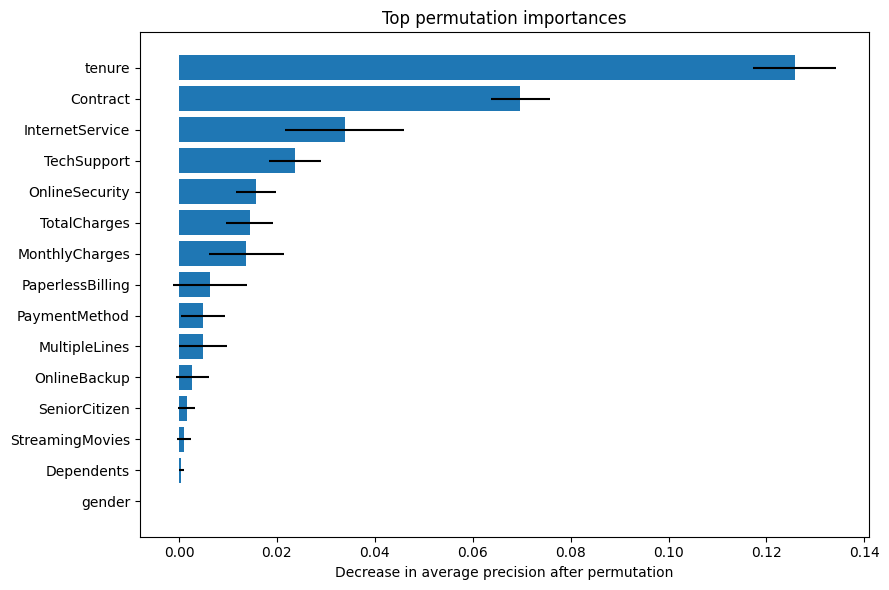

In [17]:
# Fit the selected base pipeline on training data before permutation analysis.
best_pipeline.fit(X_train, y_train)
perm = permutation_importance(
    best_pipeline, X_test, y_test, scoring="average_precision",
    n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(15).round(4))

top = importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Decrease in average precision after permutation")
plt.title("Top permutation importances")
plt.tight_layout()
plt.show()

## 11. SHAP explanations

SHAP estimates how each feature contributes to a model prediction relative to a background dataset. The explanation below targets the selected base pipeline's churn probability; it is useful for feature-level interpretation but should not be treated as causal evidence. The calibrated model is used for calibrated probabilities and final threshold decisions.

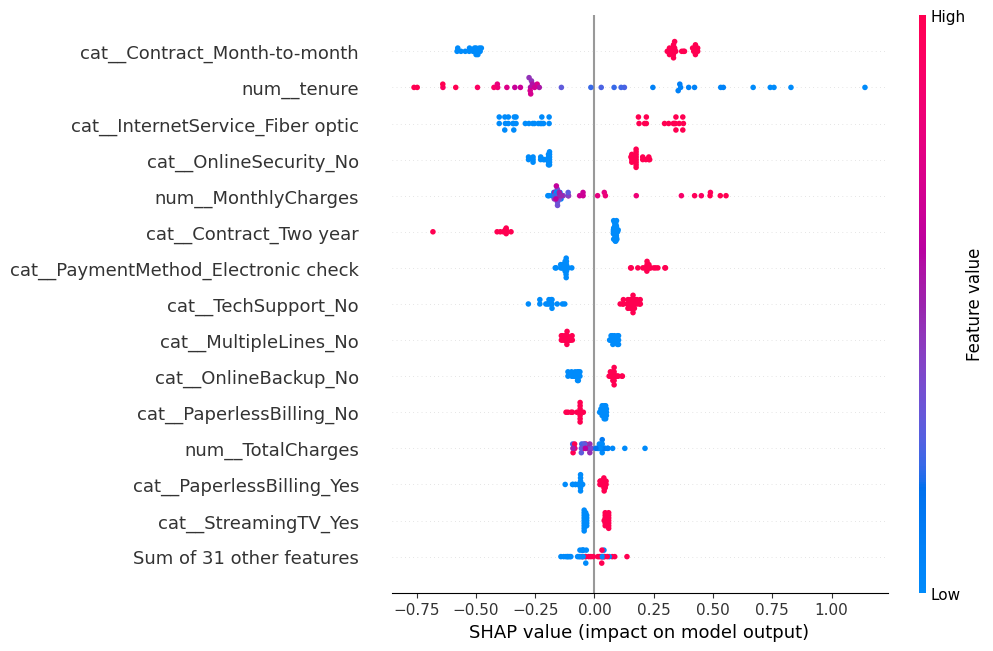

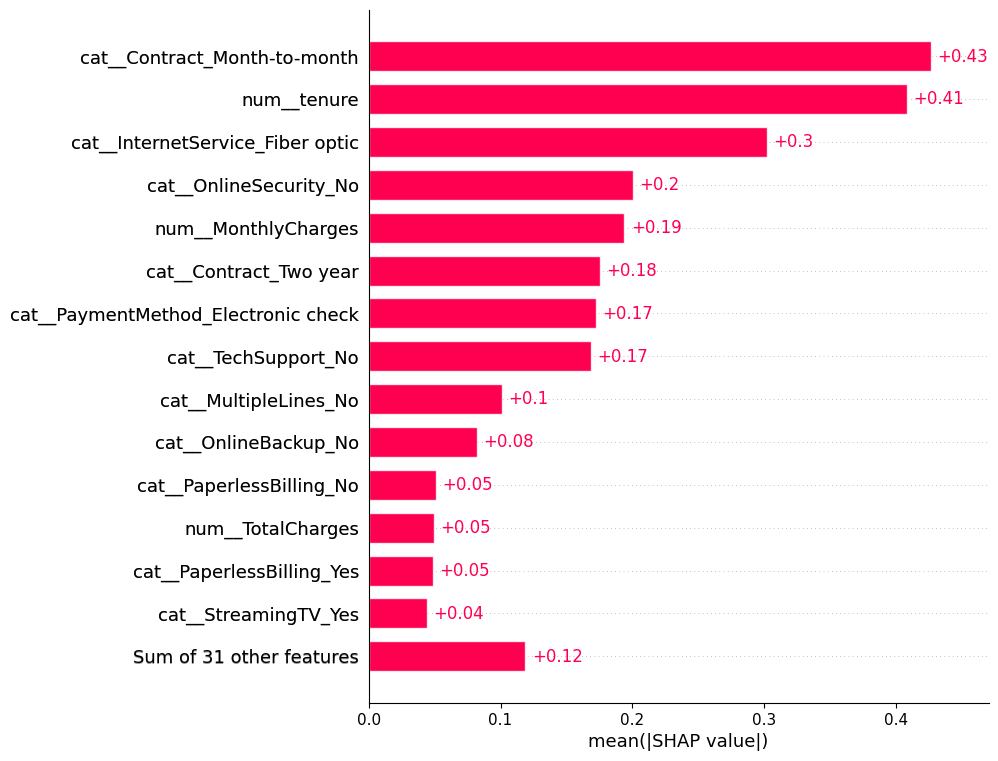

In [18]:
try:
    import shap

    # Explain the fitted base pipeline selected by CV. Transform with its fitted preprocessor.
    fitted_base = best_pipeline.fit(X_train, y_train)
    X_background_raw = X_train.sample(min(100, len(X_train)), random_state=RANDOM_STATE)
    X_explain_raw = X_test.sample(min(40, len(X_test)), random_state=RANDOM_STATE)

    X_background_transformed = fitted_base.named_steps["preprocess"].transform(X_background_raw)
    X_explain_transformed = fitted_base.named_steps["preprocess"].transform(X_explain_raw)
    feature_names = fitted_base.named_steps["preprocess"].get_feature_names_out()

    # SHAP's automatic explainer selects a suitable explainer for the underlying estimator.
    shap_explainer = shap.Explainer(
        fitted_base.named_steps["model"],
        X_background_transformed,
        feature_names=feature_names
    )
    shap_values = shap_explainer(X_explain_transformed)

    # Binary classifiers may return (rows, features, classes); explain the churn class.
    if len(shap_values.values.shape) == 3:
        shap_values_churn = shap_values[:, :, 1]
    else:
        shap_values_churn = shap_values

    shap.plots.beeswarm(shap_values_churn, max_display=15)
    shap.plots.bar(shap_values_churn, max_display=15)

except ImportError:
    print("SHAP is not installed. Install it with: pip install shap")
except Exception as exc:
    print("SHAP explanation could not be generated in this environment:", repr(exc))
    print("Try upgrading SHAP and restarting the notebook kernel.")

## 12. Create a scored customer list
Use the probabilities to prioritize review, not as an automatic reason to deny service or make adverse decisions. Confirm any campaign action against business rules and customer preferences.

In [19]:
scored_test = X_test.copy()
scored_test["actual_churn"] = y_test
scored_test["churn_probability"] = test_prob
scored_test["predicted_churn_at_selected_threshold"] = test_pred_tuned
scored_test = scored_test.sort_values("churn_probability", ascending=False)
display(scored_test.head(10))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual_churn,churn_probability,predicted_churn_at_selected_threshold
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.912911,1
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.903397,1
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.896539,1
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.875067,1
6748,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.00,85.00,1,0.873911,1
6623,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,76.45,76.45,1,0.869640,1
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.869546,1
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.869546,1
642,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,89.55,89.55,1,0.867514,1
2397,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,88.35,88.35,1,0.864683,1


## 13. Export the complete pipeline
Saving the full pipeline ensures the same imputation, scaling, encoding and model steps are reused at inference time.

In [20]:
MODEL_PATH = Path("telecom_churn_pipeline.joblib")
joblib.dump({
    "pipeline": calibrated_model,
    "threshold": chosen_threshold,
    "economics": {
        "contact_cost_inr": CONTACT_COST_INR,
        "monthly_contribution_inr": MONTHLY_CONTRIBUTION_INR,
        "months_of_value_saved": MONTHS_OF_VALUE_SAVED,
        "campaign_save_probability": CAMPAIGN_SAVE_PROBABILITY,
        "weekly_contact_capacity": WEEKLY_CONTACT_CAPACITY,
    },
    "model_name": best_name,
    "feature_columns": X_train.columns.tolist()
}, MODEL_PATH)
print(f"Saved: {MODEL_PATH.resolve()}")

Saved: /content/telecom_churn_pipeline.joblib


## 14. Example: score new customers
Supply a DataFrame with the same raw feature columns as `X_train` (do not include `customerID` or `Churn`).

In [21]:
# Example using a few real held-out records as a demonstration.
# Replace this with a new-customer DataFrame in production.
demo_customers = X_test.head(3).copy()
loaded = joblib.load(MODEL_PATH)
demo_prob = loaded["pipeline"].predict_proba(demo_customers)[:, 1]
demo_output = pd.DataFrame({
    "churn_probability": demo_prob,
    "flag_for_review": demo_prob >= loaded["threshold"]
}, index=demo_customers.index)
display(demo_output)

,churn_probability,flag_for_review
437,0.038622,False
2280,0.732291,True
2235,0.069300,False
